**GitHub repository:** https://github.com/Enne08/online-retail-dashboard.git

**Video walkthrough:** (link to be added)

# Online Retail Sales Analysis and Interactive Dashboard

## Introduction

This notebook analyses transaction data from a UK based online gift wholesaler. The company has grown quickly but has not yet analysed its sales data, so managers do not have a clear picture of **which products drive revenue, which countries matter most, and how sales change over time**.

As the company's data analyst, I will:

1. **Assess data quality**: inspect the structure and find missing values, duplicates, outliers and invalid records.
2. **Clean and prepare the data**: remove or correct invalid entries, convert data types and create useful new variables.
3. **Explore the data (EDA)**: use descriptive statistics and a range of charts to find patterns in products, customers, countries and time.
4. **Build an interactive dashboard**: give managers a simple tool with filters to explore revenue, product performance and regional patterns.

 **Dataset:** Online Retail dataset (Chen, 2015), provided on Moodle. It contains 541,909 transactions from a UK-based online gift wholesaler between 1 December 2010 and 9 December 2011, and was first analysed by Chen, Sain and Guo (2012). The data file is not uploaded to GitHub; to run this notebook, place `Online_Retail.xlsx` in a `data/` folder. All outputs are saved in the notebook, so results can be viewed without running the code.

## 1. Data Loading and Quality Assessment

Before analysing anything, I need to understand the structure of the data and check its quality. Poor quality data (missing values, duplicates or invalid records) would give managers misleading results.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_excel("data/Online_Retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 541909 | Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
df.describe().round(2)

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386048,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


### 1.1 Missing values

In [6]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "% of rows": (df.isna().mean() * 100).round(2)
})
missing

,Missing values,% of rows
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


### 1.2 Duplicates and invalid records

In [7]:
checks = {
    "Exact duplicate rows": df.duplicated().sum(),
    "Cancelled invoices (InvoiceNo starts with 'C')": df["InvoiceNo"].str.startswith("C").sum(),
    "Quantity zero or negative": (df["Quantity"] <= 0).sum(),
    "UnitPrice zero or negative": (df["UnitPrice"] <= 0).sum(),
}
pd.Series(checks, name="Number of rows").to_frame()

,Number of rows
Exact duplicate rows,5268
Cancelled invoices (InvoiceNo starts with 'C'),9288
Quantity zero or negative,10624
UnitPrice zero or negative,2517


In [8]:
non_product = df[~df["StockCode"].str.match(r"^\d")]["StockCode"].value_counts()
non_product.head(10)

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
Name: count, dtype: int64

In [9]:
print("Unique invoices:  ", df["InvoiceNo"].nunique())
print("Unique products:  ", df["StockCode"].nunique())
print("Unique customers: ", df["CustomerID"].nunique())
print("Countries:        ", df["Country"].nunique())
print("Date range:       ", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Unique invoices:   25900
Unique products:   4070
Unique customers:  4372
Countries:         38
Date range:        2010-12-01 08:26:00 to 2011-12-09 12:50:00


### 1.3 Outliers

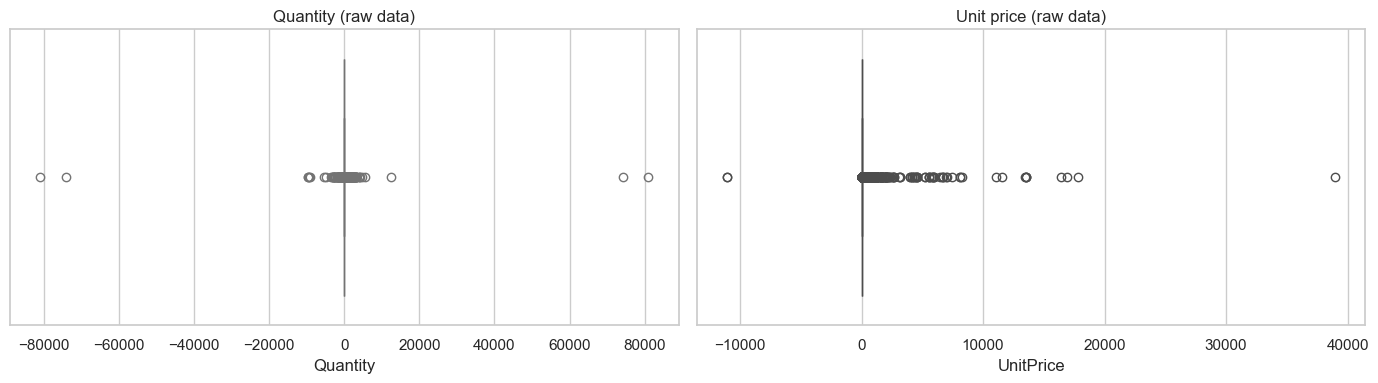

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df["Quantity"], ax=axes[0], color="lightgreen")
axes[0].set_title("Quantity (raw data)")

sns.boxplot(x=df["UnitPrice"], ax=axes[1], color="orange")
axes[1].set_title("Unit price (raw data)")

plt.tight_layout()
plt.show()

df.loc[df["Quantity"].abs().nlargest(4).index,
       ["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]]

### 1.4 Data quality summary

| Issue | Rows affected | What it means for the business |
|---|---|---|
| Missing CustomerID | 135,080 (24.9%) | Sales can't be linked to a customer, so these are useful for revenue but not for customer analysis |
| Missing Description | 1,454 (0.27%) | Product unknown, and most also have a price of 0 |
| Exact duplicates | 5,268 | Likely system errors that would double-count sales |
| Cancelled invoices ("C") | 9,288 | Orders reversed after being placed, so they're not real sales |
| Quantity ≤ 0 | 10,624 | Mostly cancellations, plus stock write-offs (e.g. "damaged", "thrown away") |
| UnitPrice ≤ 0 | 2,517 | Free items or adjustments, with no revenue |
| Non-product codes | ~2,800 | Postage, fees and manual adjustments, which aren't product sales |
| Extreme outliers | A few rows | Very large orders (e.g. 80,995 units) that were immediately cancelled |

**Limitations:** the data covers just over one year (Dec 2010 to Dec 2011), so seasonal patterns are based on a single year. December 2011 is only partly included (up to 9 December). Most transactions come from the United Kingdom, so the other countries have much less data.

## 2. Data Cleaning and Preparation

In this section I fix the data quality problems found in Section 1. Each decision is based on **business logic**: the goal is a dataset where every row represents a **real product sale**, so that revenue and product figures shown to managers are accurate.

In [11]:
clean = df.copy()
steps = [("Original data", len(clean))]

# 1. Remove exact duplicate rows
clean = clean.drop_duplicates()
steps.append(("1. Remove exact duplicates", len(clean)))

# 2. Remove cancelled invoices (InvoiceNo starting with "C")
clean = clean[~clean["InvoiceNo"].str.startswith("C")]
steps.append(("2. Remove cancelled invoices", len(clean)))

# 3. Keep only positive quantities and prices
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]
steps.append(("3. Remove zero/negative quantity or price", len(clean)))

# 4. Remove non-product codes (postage, fees, adjustments, gift vouchers)
NON_PRODUCT = ["POST", "DOT", "M", "m", "C2", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK", "D"]
fee_rows = clean["StockCode"].isin(NON_PRODUCT) | clean["StockCode"].str.startswith("gift_")
clean = clean[~fee_rows]
steps.append(("4. Remove postage, fees and gift vouchers", len(clean)))

# 5. Remove 3 extreme orders that were reversed straight after being placed
clean = clean[~clean["InvoiceNo"].isin(["581483", "541431", "556444"])]
steps.append(("5. Remove 3 extreme orders that were reversed", len(clean)))

summary = pd.DataFrame(steps, columns=["Step", "Rows remaining"])
summary["Rows removed"] = (-summary["Rows remaining"].diff()).fillna(0).astype(int)
print(f"Kept {len(clean) / len(df):.1%} of the original rows")
summary

Kept 96.4% of the original rows


,Step,Rows remaining,Rows removed
0,Original data,541909,0
1,1. Remove exact duplicates,536641,5268
2,2. Remove cancelled invoices,527390,9251
3,3. Remove zero/negative quantity or price,524878,2512
4,"4. Remove postage, fees and gift vouchers",522540,2338
5,5. Remove 3 extreme orders that were reversed,522537,3


### 2.1 Cleaning decisions

| Step | Rows removed | Why (business logic) |
|---|---|---|
| 1. Exact duplicates | 5,268 | Identical rows (same invoice, product, time and quantity) are system errors. Keeping them would **double-count** sales. |
| 2. Cancelled invoices | 9,251 | Orders starting with "C" were reversed, so the company never earned that money. They are not real sales. |
| 3. Zero/negative quantity or price | 2,512 | Negative quantities without a "C" are stock write-offs (e.g. "damaged", "thrown away"). Price £0 rows are free items or adjustments. None of these is revenue. Removing them also removed **all 1,454 rows with a missing Description**, because those were all zero-price stock adjustments. |
| 4. Postage, fees and gift vouchers | 2,338 | Codes like POST, DOT (postage), M (manual adjustment), BANK CHARGES and AMAZONFEE are **charges, not products**. Including them would distort product rankings (e.g. "Postage" would appear as a top-selling product). |
| 5. Extreme reversed orders | 3 | Section 1 showed two huge orders (80,995 and 74,215 units) cancelled minutes later. A third order of 60 picnic baskets (£38,970) was reversed by a manual refund of exactly £38,970 three minutes later. These sales never really happened, and they would distort every chart. |

**What I did not remove:** large wholesale orders (up to 4,800 units) that were **not** cancelled. This company is a wholesaler, so big orders are genuine and important for revenue.

### 2.2 Missing values and data types

In [13]:
print("Missing values after cleaning:")
print(clean.isna().sum())

clean["CustomerID"] = clean["CustomerID"].astype("Int64").astype(str).replace("<NA>", "Unknown")
clean["Country"] = clean["Country"].replace({"EIRE": "Ireland", "RSA": "South Africa"})

clean.dtypes

Missing values after cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131387
Country             0
dtype: int64


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID             object
Country                object
dtype: object

**Missing CustomerID (about 131,000 rows):** I **kept** these rows and labelled them "Unknown", instead of deleting them. They are real sales with a valid product, price and country, so removing them would **understate revenue by about a quarter**. They are left out only when analysing individual customers.

I also renamed "EIRE" to "Ireland" and "RSA" to "South Africa" so country names are clear for a non-technical audience.

### 2.3 Derived variables

I created new columns that the analysis and dashboard need:

| New column | How it is calculated | Why it is useful |
|---|---|---|
| `TotalPrice` | Quantity × UnitPrice | The **revenue** from each line, needed for every sales chart |
| `YearMonth` | Month of InvoiceDate (e.g. "2011-05") | To show sales **over time** by month |
| `DayOfWeek` | Day name of InvoiceDate | To compare sales on different days |
| `Hour` | Hour of InvoiceDate | To see what time of day customers order |

In [14]:
clean["TotalPrice"] = clean["Quantity"] * clean["UnitPrice"]
clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["DayOfWeek"] = clean["InvoiceDate"].dt.day_name()
clean["Hour"] = clean["InvoiceDate"].dt.hour

print(f"Total revenue after cleaning: £{clean['TotalPrice'].sum():,.0f}")
clean[["InvoiceDate", "Quantity", "UnitPrice", "TotalPrice", "YearMonth", "DayOfWeek", "Hour"]].head()

Total revenue after cleaning: £9,962,596


,InvoiceDate,Quantity,UnitPrice,TotalPrice,YearMonth,DayOfWeek,Hour
0,2010-12-01 08:26:00,6,2.55,15.30,2010-12,Wednesday,8
1,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8
2,2010-12-01 08:26:00,8,2.75,22.00,2010-12,Wednesday,8
3,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8
4,2010-12-01 08:26:00,6,3.39,20.34,2010-12,Wednesday,8


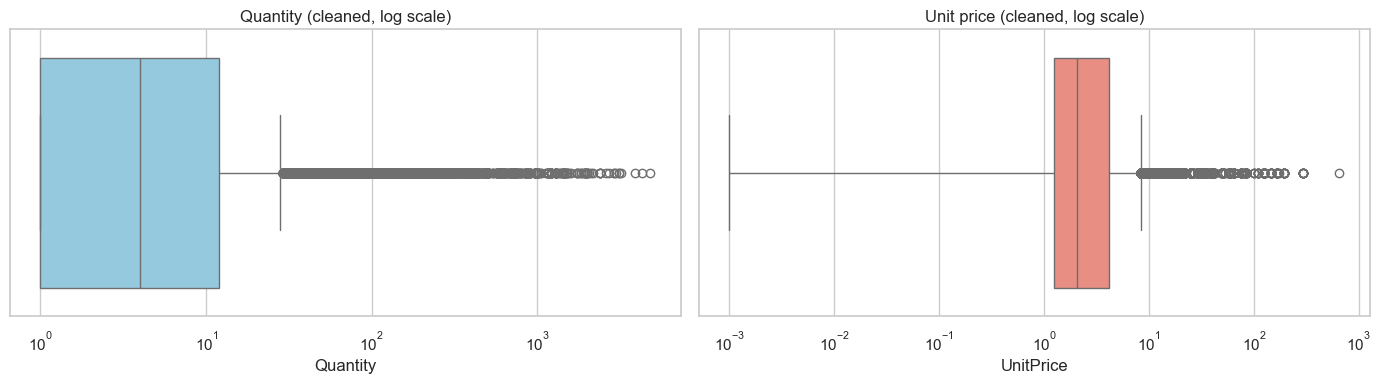

,Quantity,UnitPrice,TotalPrice
count,522537.00,522537.00,522537.00
mean,10.35,3.27,19.07
std,37.85,4.30,65.31
min,1.00,0.00,0.00
25%,1.00,1.25,3.90
50%,4.00,2.08,9.90
75%,12.00,4.13,17.70
max,4800.00,649.50,7144.72


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=clean["Quantity"], ax=axes[0], color="skyblue")
axes[0].set_xscale("log")
axes[0].set_title("Quantity (cleaned, log scale)")

sns.boxplot(x=clean["UnitPrice"], ax=axes[1], color="salmon")
axes[1].set_xscale("log")
axes[1].set_title("Unit price (cleaned, log scale)")

plt.tight_layout()
plt.show()

clean[["Quantity", "UnitPrice", "TotalPrice"]].describe().round(2)

After cleaning, there are no negative values. Because the data is very **right skewed** (most orders are small, with a few very large wholesale orders), I used a log scale so both can be seen. Half of all order lines are for **4 items or fewer**, while the largest genuine order is 4,800 units. I kept these large orders because they are real wholesale sales.

In [16]:
clean.to_csv("data/online_retail_clean.csv", index=False)
print("Saved cleaned data:", clean.shape)

Saved cleaned data: (522537, 12)


### 2.4 Cleaning summary

The cleaned dataset has **522,537 rows (96.4% of the original)** and **£9.96 million in revenue**. Every row now represents a real product sale with a positive quantity and price, a product description, a clear country name and a calculated line value. The main limitation is that about 25% of sales have no customer ID, so customer-level analysis is based on the remaining 75%.

## 3. Exploratory Data Analysis (EDA)

In this section I explore the cleaned data to answer the key business questions:

1. **How big is the business, and what does a typical order look like?**
2. **How do sales change over time?** (months and days of the week)
3. **Which products drive revenue?**
4. **Which countries are most important?**
5. **How are order values distributed, and who are the key customers?**

To save time, I load the cleaned file saved in Section 2 instead of repeating the cleaning.

In [17]:
import matplotlib.ticker as mticker

sales = pd.read_csv("data/online_retail_clean.csv", parse_dates=["InvoiceDate"],
                    dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
print("Rows:", len(sales))

Rows: 522537


### 3.1 Descriptive statistics

The dataset has one row per **product line**, so a single order (invoice) can have many rows. To understand typical orders, I first group the rows by invoice.

In [18]:
orders = sales.groupby("InvoiceNo").agg(
    OrderValue=("TotalPrice", "sum"),
    Items=("Quantity", "sum"),
    Lines=("StockCode", "count"),
    CustomerID=("CustomerID", "first"),
    Country=("Country", "first"),
)

kpis = {
    "Total revenue (£)": f"{sales['TotalPrice'].sum():,.0f}",
    "Number of orders": f"{len(orders):,}",
    "Number of customers (known)": f"{sales.loc[sales['CustomerID'] != 'Unknown', 'CustomerID'].nunique():,}",
    "Number of products": f"{sales['StockCode'].nunique():,}",
    "Number of countries": sales["Country"].nunique(),
    "Average order value (£)": f"{orders['OrderValue'].mean():,.2f}",
    "Median order value (£)": f"{orders['OrderValue'].median():,.2f}",
}
pd.Series(kpis, name="Value").to_frame()

,Value
Total revenue (£),"9,962,596"
Number of orders,"19,770"
Number of customers (known),"4,333"
Number of products,"3,907"
Number of countries,38
Average order value (£),503.92
Median order value (£),302.20


In [19]:
orders[["OrderValue", "Items", "Lines"]].describe().round(2)

,OrderValue,Items,Lines
count,19770.00,19770.00,19770.00
mean,503.92,273.45,26.43
std,1146.07,559.73,47.34
min,0.38,1.00,1.00
25%,151.66,71.00,6.00
50%,302.20,152.00,15.00
75%,481.32,297.00,29.00
max,52940.94,15049.00,1112.00


**Interpretation:**
- After cleaning, the business made **£9.96 million** from **19,770 orders** placed by **4,333 known customers** in **38 countries**, selling **3,907 different products**.
- The **average order is £504**, but the **median is only £302**. The mean is much higher than the median because a small number of very large orders (up to £52,941) pull the average up, so the **median is a better measure of a "typical" order**.
- A typical order contains **15 different products** and **152 items**. This confirms the customers are mainly **businesses buying in bulk** (e.g. gift shops), not individual shoppers.

### 3.2 Sales over time: monthly revenue (line chart)

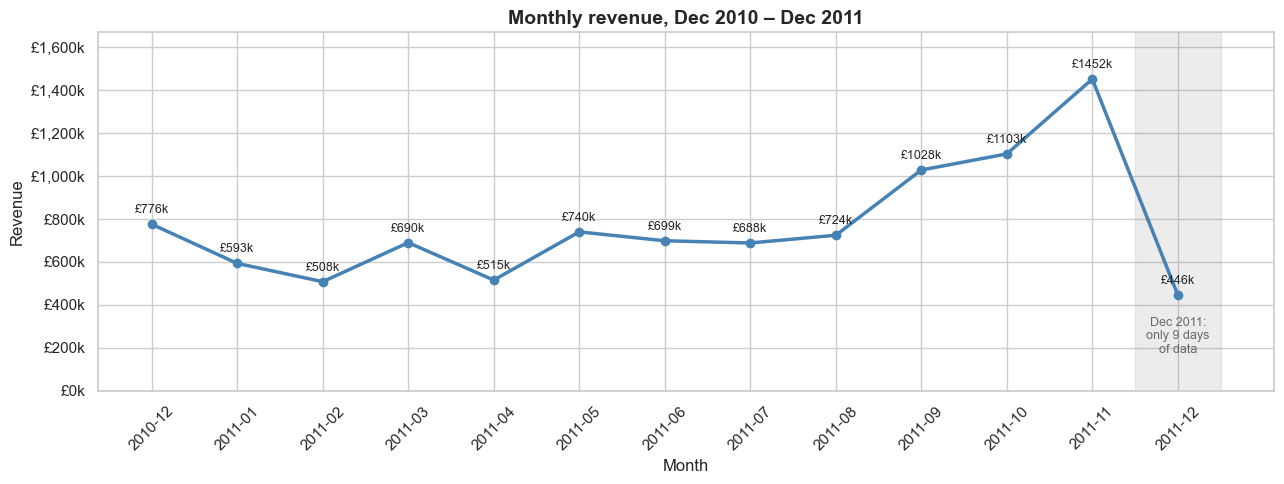

In [20]:
monthly = sales.groupby("YearMonth").agg(Revenue=("TotalPrice", "sum"),
                                         Orders=("InvoiceNo", "nunique")).reset_index()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly["YearMonth"], monthly["Revenue"], marker="o", linewidth=2.5, color="steelblue")

for x, y in zip(monthly["YearMonth"], monthly["Revenue"]):
    ax.annotate(f"£{y/1000:.0f}k", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)

ax.axvspan(11.5, 12.5, color="grey", alpha=0.15)
ax.text(12, monthly["Revenue"].max() * 0.12, "Dec 2011:\nonly 9 days\nof data",
        ha="center", fontsize=9, color="dimgrey")

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"£{v/1000:,.0f}k"))
ax.set_ylim(0, monthly["Revenue"].max() * 1.15)
ax.set_title("Monthly revenue, Dec 2010 – Dec 2011", fontsize=14, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Why a line chart:** Month is an ordered time variable, and the question is how revenue **changes over time**. A line chart connects the months in order, which makes rises, falls and trends easy to see. I labelled each point with its value so managers can read exact figures, started the y-axis at zero to avoid exaggerating changes, and shaded December 2011 because it is incomplete.
Line charts are recommended for showing continuous data over time, while bar charts suit comparisons between categories (Knaflic, 2015).

**What it shows:**
- Revenue was fairly **steady at about £500k–£750k per month** from January to August 2011, with the lowest point in **February (£508k)**.
- From September, revenue **rises sharply** and peaks in **November 2011 at £1.45 million**, almost three times February. The data does not show *why*, but because the company sells gifts to other businesses, a likely explanation is that retailers stock up before Christmas. Since the data covers only one year, this seasonal pattern cannot be confirmed for other years.
- The drop in December 2011 is **not a real decline**: the data stops on 9 December.
- **Business implication:** because September to November brought in the most revenue, managers should plan stock, staff and delivery capacity for this period. Quieter months, such as February (the lowest month), could be targeted with promotions.

### 3.3 Sales by day of the week (bar chart)

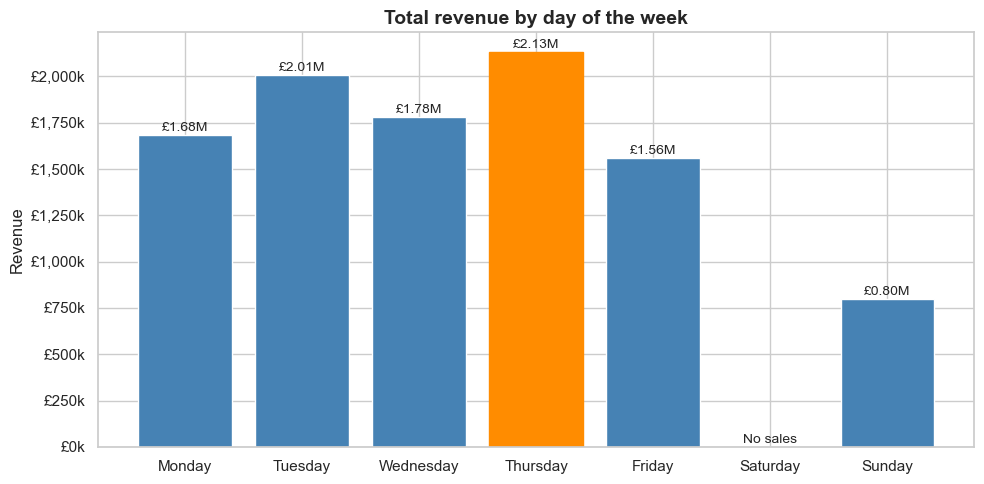

In [21]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = sales.groupby("DayOfWeek")["TotalPrice"].sum().reindex(day_order, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(by_day.index, by_day.values, color="steelblue")
bars[by_day.values.argmax()].set_color("darkorange")

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 20000,
            f"£{h/1e6:.2f}M" if h > 0 else "No sales", ha="center", fontsize=10)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"£{v/1000:,.0f}k"))
ax.set_title("Total revenue by day of the week", fontsize=14, weight="bold")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.show()

**Why a bar chart:** Day of the week is a **categorical** variable, and the question is to **compare** revenue between days. Bar lengths are easy to compare, and I kept the days in calendar order (not sorted by value) because people naturally read the week from Monday to Sunday. The best day is highlighted in orange.

**What it shows:**
- **Thursday** is the busiest day (**£2.13M**), followed by Tuesday (£2.01M).
- There are **no sales recorded on Saturdays**, and Sunday is the quietest day with sales (£0.80M). The data does not explain this; one possibility is that orders are not processed on Saturdays, which would fit a business to business wholesaler whose customers order during the working week.
- **Business implication:** staffing and customer service should be strongest from Tuesday to Thursday, and any weekend promotions are unlikely to be effective.

## References

Chen, D. (2015) *Online Retail* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5BW33

Chen, D., Sain, S.L. and Guo, K. (2012) 'Data mining for the online retail industry: a case study of RFM model-based customer segmentation using data mining', *Journal of Database Marketing & Customer Strategy Management*, 19(3), pp. 197–208.

Few, S. (2012) *Show Me the Numbers: Designing Tables and Graphs to Enlighten*. 2nd edn. Burlingame, CA: Analytics Press.

Knaflic, C.N. (2015) *Storytelling with Data: A Data Visualization Guide for Business Professionals*. Hoboken, NJ: Wiley.

The pandas development team (2024) *pandas* [Software]. Available at: https://pandas.pydata.org

Hunter, J.D. (2007) 'Matplotlib: a 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90–95.

Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), p. 3021.